# 03 · Evaluación en el conjunto de test

Entrada: `datos_cleveland_limpios.csv`, `modelos_tfm.joblib`.
Salida: tablas y figuras en `figures/` y `predicciones_test.csv`. El conjunto de test se usa una sola vez.

In [1]:
import os, glob, shutil
import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve

SEMILLA = 42
os.makedirs("figures", exist_ok=True)

try:
    from google.colab import files
    if not (glob.glob("datos_cleveland_limpios*.csv") and glob.glob("modelos_tfm*.joblib")):
        files.upload()
except ImportError:
    pass

df = pd.read_csv(sorted(glob.glob("datos_cleveland_limpios*.csv"))[0])
paquete = joblib.load(sorted(glob.glob("modelos_tfm*.joblib"))[0])
if sklearn.__version__ != paquete["sklearn"]:
    print(f"AVISO: modelos guardados con scikit-learn {paquete['sklearn']}, "
          f"entorno actual {sklearn.__version__}. Si hay errores, reejecutar el cuaderno 02.")
modelos, umbrales, TABLA_DF = paquete["modelos"], paquete["umbrales"], paquete["tabla_df"]

X = df.drop(columns=["num", "enfermedad", "restecg"])
y = df["enfermedad"]
X_test, y_test = X.loc[paquete["indices_test"]], y.loc[paquete["indices_test"]].values
print(f"Test: {len(y_test)} pacientes, {y_test.sum()} eventos")

Saving modelos_tfm.joblib to modelos_tfm.joblib
Saving datos_cleveland_limpios (1).csv to datos_cleveland_limpios (1).csv
Test: 61 pacientes, 28 eventos


In [2]:
def prob_diamond_forrester(datos):
    decada = ((datos["age"] // 10) - 3).clip(0, 3).astype(int)
    return np.array([TABLA_DF[(int(cp), int(sx))][d] / 100
                     for cp, sx, d in zip(datos["cp"], datos["sex"], decada)])

prob = {"Diamond-Forrester (tabla)": prob_diamond_forrester(X_test)}
for nombre, m in modelos.items():
    prob[nombre] = m["modelo"].predict_proba(X_test[m["variables"]])[:, 1]

ORDEN = ["Diamond-Forrester (tabla)", "Logística DF reentrenada", "Logística consulta",
         "Random Forest consulta", "Logística completa", "Random Forest completo"]

## 1. Discriminación (AUC con IC 95 % por bootstrap, B = 2000)

In [3]:
rng = np.random.default_rng(SEMILLA)
B = 2000
muestras = []
while len(muestras) < B:
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].min() != y_test[idx].max():
        muestras.append(idx)

auc_boot = {n: np.array([roc_auc_score(y_test[i], prob[n][i]) for i in muestras]) for n in ORDEN}
ic = lambda v: np.percentile(v, [2.5, 97.5])

tabla_auc = pd.DataFrame({
    "AUC": [roc_auc_score(y_test, prob[n]) for n in ORDEN],
    "IC 95 % inf": [ic(auc_boot[n])[0] for n in ORDEN],
    "IC 95 % sup": [ic(auc_boot[n])[1] for n in ORDEN],
}, index=ORDEN).round(3)
tabla_auc

,AUC,IC 95 % inf,IC 95 % sup
Diamond-Forrester (tabla),0.357,0.211,0.504
Logística DF reentrenada,0.869,0.760,0.956
Logística consulta,0.871,0.764,0.957
Random Forest consulta,0.872,0.765,0.962
Logística completa,0.962,0.906,1.000
Random Forest completo,0.950,0.890,0.991


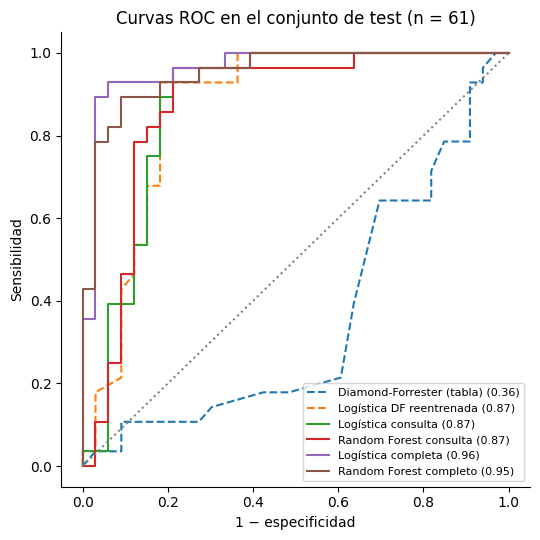

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for n in ORDEN:
    fpr, tpr, _ = roc_curve(y_test, prob[n])
    ax.plot(fpr, tpr, "--" if "Diamond" in n or "DF" in n else "-",
            label=f"{n} ({tabla_auc.loc[n, 'AUC']:.2f})")
ax.plot([0, 1], [0, 1], ":", color="grey")
ax.set_xlabel("1 − especificidad")
ax.set_ylabel("Sensibilidad")
ax.set_title(f"Curvas ROC en el conjunto de test (n = {len(y_test)})")
ax.legend(fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig_roc_test.png", dpi=300)
plt.show()

## 2. Diferencias pareadas de AUC

In [5]:
COMPARACIONES = [
    ("Logística DF reentrenada", "Diamond-Forrester (tabla)", "¿Reentrenar mejora la tabla clásica?"),
    ("Logística consulta", "Logística DF reentrenada", "¿Aportan PA, colesterol, glucemia y ECG?"),
    ("Logística completa", "Logística consulta", "¿Aportan ergometría, fluoroscopia y talio?"),
    ("Random Forest completo", "Logística completa", "¿Mejora el Random Forest a la logística?"),
    ("Random Forest consulta", "Logística consulta", "Ídem, con variables de consulta"),
    ("Logística completa", "Diamond-Forrester (tabla)", "Modelo final frente a la tabla clásica"),
]
filas = []
for a, b, pregunta in COMPARACIONES:
    lo, hi = ic(auc_boot[a] - auc_boot[b])
    obs = tabla_auc.loc[a, "AUC"] - tabla_auc.loc[b, "AUC"]
    filas.append([pregunta, f"{a} − {b}", round(obs, 3), round(lo, 3), round(hi, 3),
                  "No" if lo <= 0 <= hi else "Sí"])
tabla_comp = pd.DataFrame(filas, columns=["Pregunta", "Comparación", "Diferencia AUC",
                                          "IC 95 % inf", "IC 95 % sup", "¿IC excluye 0?"])
tabla_comp

,Pregunta,Comparación,Diferencia AUC,IC 95 % inf,IC 95 % sup,¿IC excluye 0?
0,¿Reentrenar mejora la tabla clásica?,Logística DF reentrenada − Diamond-Forrester (...,0.512,0.333,0.685,Sí
1,"¿Aportan PA, colesterol, glucemia y ECG?",Logística consulta − Logística DF reentrenada,0.002,-0.028,0.038,No
2,"¿Aportan ergometría, fluoroscopia y talio?",Logística completa − Logística consulta,0.091,-0.004,0.203,No
3,¿Mejora el Random Forest a la logística?,Random Forest completo − Logística completa,-0.012,-0.038,0.010,No
4,"Ídem, con variables de consulta",Random Forest consulta − Logística consulta,0.001,-0.031,0.036,No
5,Modelo final frente a la tabla clásica,Logística completa − Diamond-Forrester (tabla),0.605,0.453,0.752,Sí


## 3. Calibración

In [6]:
tabla_cal = pd.DataFrame({
    "Brier": [brier_score_loss(y_test, prob[n]) for n in ORDEN],
    "Media predicha": [prob[n].mean() for n in ORDEN],
    "Proporción observada": [y_test.mean()] * len(ORDEN),
}, index=ORDEN).round(3)
brier_referencia = brier_score_loss(y_test, np.full(len(y_test), y_test.mean()))
print(f"Brier de referencia (prevalencia para todos): {brier_referencia:.3f}")
tabla_cal

Brier de referencia (prevalencia para todos): 0.248


,Brier,Media predicha,Proporción observada
Diamond-Forrester (tabla),0.406,0.212,0.459
Logística DF reentrenada,0.154,0.428,0.459
Logística consulta,0.147,0.433,0.459
Random Forest consulta,0.149,0.451,0.459
Logística completa,0.086,0.512,0.459
Random Forest completo,0.111,0.479,0.459


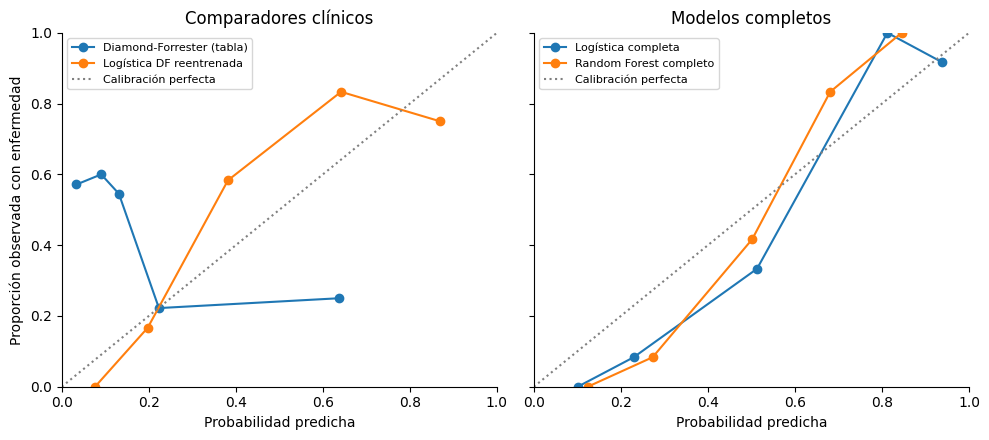

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
grupos = [["Diamond-Forrester (tabla)", "Logística DF reentrenada"],
          ["Logística completa", "Random Forest completo"]]
for ax, nombres in zip(axes, grupos):
    for n in nombres:
        obs, pred = calibration_curve(y_test, prob[n], n_bins=5, strategy="quantile")
        ax.plot(pred, obs, "o-", label=n)
    ax.plot([0, 1], [0, 1], ":", color="grey", label="Calibración perfecta")
    ax.set_xlabel("Probabilidad predicha")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Proporción observada con enfermedad")
axes[0].set_title("Comparadores clínicos")
axes[1].set_title("Modelos completos")
plt.tight_layout()
plt.savefig("figures/fig_calibracion_test.png", dpi=300)
plt.show()

## 4. Rendimiento clínico (umbral 0,5 y umbral de descarte; IC de Wilson)

In [8]:
def wilson(k, n, z=1.96):
    if n == 0:
        return ""
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return f"{max(0, centro - mitad):.3f}–{min(1, centro + mitad):.3f}"

def metricas(y_real, p, umbral):
    tn, fp, fn, tp = confusion_matrix(y_real, (p >= umbral).astype(int), labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    return {"Umbral": round(umbral, 3), "VP": tp, "FP": fp, "FN": fn, "VN": tn,
            "Sensibilidad": div(tp, tp + fn), "IC 95 % sens.": wilson(tp, tp + fn),
            "Especificidad": div(tn, tn + fp), "IC 95 % esp.": wilson(tn, tn + fp),
            "VPP": div(tp, tp + fp), "IC 95 % VPP": wilson(tp, tp + fp),
            "VPN": div(tn, tn + fn), "IC 95 % VPN": wilson(tn, tn + fn)}

tabla_clin = pd.DataFrame([
    {"Modelo": n, "Criterio": etiqueta, **metricas(y_test, prob[n], u)}
    for n in ORDEN for etiqueta, u in [("0,5", 0.5), ("Rule-out", umbrales[n])]
]).set_index(["Modelo", "Criterio"])
tabla_clin.round(3)

Umbral  VP  FP  FN  VN  Sensibilidad  \
Modelo                    Criterio                                         
Diamond-Forrester (tabla) 0,5        0.500   3   6  25  27         0.107   
                          Rule-out   0.055  22  28   6   5         0.786   
Logística DF reentrenada  0,5        0.500  17   5  11  28         0.607   
                          Rule-out   0.265  26  11   2  22         0.929   
Logística consulta        0,5        0.500  20   5   8  28         0.714   
                          Rule-out   0.248  27  10   1  23         0.964   
Random Forest consulta    0,5        0.500  21   4   7  29         0.750   
                          Rule-out   0.325  27  10   1  23         0.964   
Logística completa        0,5        0.500  26   5   2  28         0.929   
                          Rule-out   0.300  28  11   0  22         1.000   
Random Forest completo    0,5        0.500  26   6   2  27         0.929   
                          Rule-out   0.330  27  11   1  22         0.964   

                                   IC 95 % sens.  Especificidad IC 95 % esp.  \
Modelo                    Criterio                                             
Diamond-Forrester (tabla) 0,5        0.037–0.272          0.818  0.656–0.914   
                          Rule-out   0.605–0.898          0.152  0.067–0.309   
Logística DF reentrenada  0,5        0.424–0.764          0.848  0.691–0.933   
                          Rule-out   0.774–0.980          0.667  0.496–0.802   
Logística consulta        0,5        0.529–0.847          0.848  0.691–0.933   
                          Rule-out   0.823–0.994          0.697  0.527–0.826   
Random Forest consulta    0,5        0.566–0.873          0.879  0.727–0.952   
                          Rule-out   0.823–0.994          0.697  0.527–0.826   
Logística completa        0,5        0.774–0.980          0.848  0.691–0.933   
                          Rule-out   0.879–1.000          0.667  0.496–0.802   
Random Forest completo    0,5        0.774–0.980          0.818  0.656–0.914   
                          Rule-out   0.823–0.994          0.667  0.496–0.802   

                                      VPP  IC 95 % VPP    VPN  IC 95 % VPN  
Modelo                    Criterio                                          
Diamond-Forrester (tabla) 0,5       0.333  0.121–0.646  0.519  0.387–0.649  
                          Rule-out  0.440  0.312–0.577  0.455  0.213–0.720  
Logística DF reentrenada  0,5       0.773  0.566–0.899  0.718  0.562–0.835  
                          Rule-out  0.703  0.542–0.825  0.917  0.742–0.977  
Logística consulta        0,5       0.800  0.609–0.911  0.778  0.619–0.883  
                          Rule-out  0.730  0.570–0.846  0.958  0.798–0.993  
Random Forest consulta    0,5       0.840  0.653–0.936  0.806  0.650–0.902  
                          Rule-out  0.730  0.570–0.846  0.958  0.798–0.993  
Logística completa        0,5       0.839  0.674–0.929  0.933  0.787–0.982  
                          Rule-out  0.718  0.562–0.835  1.000  0.851–1.000  
Random Forest completo    0,5       0.812  0.647–0.911  0.931  0.780–0.981  
                          Rule-out  0.711  0.552–0.830  0.957  0.790–0.992

## 5. Exportación

In [9]:
tabla_auc.to_csv("figures/tabla_auc_test.csv")
tabla_comp.to_csv("figures/tabla_comparaciones_auc.csv", index=False)
tabla_cal.to_csv("figures/tabla_calibracion_test.csv")
tabla_clin.round(3).to_csv("figures/tabla_rendimiento_clinico.csv")
pd.DataFrame(prob).assign(enfermedad=y_test).to_csv("predicciones_test.csv", index=False)
try:
    from google.colab import files
    shutil.make_archive("resultados_test", "zip", "figures")
    files.download("resultados_test.zip")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>